In [1]:
# =========================
# 1) Imports
# =========================
import os, math, json, copy
import numpy as np
import matplotlib.pyplot as plt

from typing import Dict, Tuple, List

from sklearn.decomposition import PCA
from sklearn.model_selection import KFold
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_squared_error

import umap
import torch
from scipy.signal import butter, filtfilt, hilbert, sawtooth
from scipy.ndimage import gaussian_filter1d
from scipy.stats import circmean, ttest_rel

# Your package
from pathlib import Path
import sys

for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    code_dir = p / "code"
    if (code_dir / "comets").exists():
        if str(code_dir) not in sys.path:
            sys.path.insert(0, str(code_dir))
        break

import comets
from comets.encoders import CEBRASKipEncoder, SkippedConvEncoderConfig
from comets.configs import ModalityConfig, SamplingConfig, TrainingConfig
from comets.heads import LinearHead

# CEBRA baseline (assume available)
import cebra

import pandas as pd


In [2]:
# =========================
# 2) Configurations (edit)
# =========================
# --- Simulation ---
SIM_SEED        = 5

# --- Evaluation control ---
N_SEEDS         = 10                # model-fit repetitions
RIDGE_ALPHA     = 0.1
TRAIN_FRAC      = 0.7
STANDARDIZE_Z   = True

# --- Quick-run switch (for sanity/style check) ---
QUICK_EPOCHS    = 2             # CoMETs epochs for dry run
FULL_EPOCHS     = 100               # CoMETs epochs for full run

# --- CoMETs hyperparams ---
WINLEN_A        = 8
WINLEN_B        = 8
EMB_A_DIM       = 32
EMB_B_DIM       = 16
BATCH_SIZE      = 256
POS_OFFSET      = 5
NEG_MASK_DIST   = 16
LR              = 1e-3
TEMPERATURE     = 1.0

ALPHA_CROSS     = 0.05 # weight cross vs within
BETA_AB         = 0.5  # balance A vs B (default equal)

PROJ_DIM        = 8

# --- CEBRA hyperparams ---
CEBRA_DIM_A     = 32
CEBRA_DIM_B     = 16
CEBRA_ITERS     = FULL_EPOCHS
CEBRA_TEMP      = 1.0

# --- Models and shuffles to run in the full sweep ---
MODELS = ("CoMETs", "PCA", "UMAP", "CEBRA")
SHUFFLES_BY_MODEL = {
    "PCA":   ["real", "channel_indep"],
    "UMAP":  ["real", "channel_indep"],
    "CEBRA": ["real", "channel_indep", "global"],
    "CoMETs": ["real", "channel_indep", "global", "lfp_only"],
}

# plotting
plt.rcParams["figure.dpi"] = 110
np.set_printoptions(suppress=True, precision=4)


In [3]:
# =========================
# 3) CONFIGURATION
# =========================
# --- Simulation ---
FS              = 250
T_SEC           = 15
MOVE_MODE       = "biased_rw"      # "constant" | "nonstationary" | "biased_rw"

# --- Cell counts ---
n_place         = 15
n_multipeak     = 10
n_noisy         = 40
n_hd            = 5
n_cells_total   = n_place + n_multipeak + n_noisy + n_hd
ALLOW_SEGMENTS = [(-1.0, -0.55), (-0.4, 0.3), (0.45, 0.85)] # (-1,1)
# ALLOW_SEGMENTS = None

# --- LFP channels ---
n_lfp           = 16

# --- Noise and coupling controls ---
NOISE_WHITE_STD = 0.30     # additive white noise
NOISE_PINK_STD  = 0.25     # low-freq pink drift
PSP_GAIN        = 0.15     # spike→LFP coupling
PHASE_POS_GAIN  = 0.5     # spatial phase modulation
AMP_POS_GAIN    = 0.00     # amplitude-position modulation
CH_PHASE_JITTER_DEG = 30.0

# --- Theta + amplitude envelopes ---
THETA_F0 = 8.0
THETA_WOBBLE1_HZ, THETA_WOBBLE1_AMP = 0.02, 0.4
THETA_WOBBLE2_HZ, THETA_WOBBLE2_AMP = 0.006, 0.2
AMP_BASE, AMP_SPEED_GAIN, AMP_DRIFT_GAIN, AMP_DRIFT_FREQ = 0.60, 0.35, 0.15, 0.015

# --- Place & multi-peak tuning strength (to modulate difficulty) ---
PF_WIDTH_RANGE = (0.10, 0.22)
PF_PEAK_HZ     = (6.0, 12.0)
PF_BASE_HZ     = (0.1, 0.4)
PF_KAPPA       = (2.0, 6.0)
MP_NUM_RANGE   = (2, 4)
MP_WIDTH_RANGE = (0.12, 0.28)
MP_AMP_RANGE   = (3.0, 7.0)
MP_KAPPA       = (1.0, 3.0)

# --- Noise cell parameters ---
NOISY_KAPPA    = (0.0, 1.0)
NOISY_RW_STD   = 0.04


print(f"Sim seed={SIM_SEED}, total cells={n_cells_total}, LFP={n_lfp}")


Sim seed=5, total cells=70, LFP=16


In [4]:
# =========================
# 3) Utilities
# =========================
def set_all_seeds(seed: int):
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def blocked_split_idx(T: int, train_frac: float):
    n_train = int(T * train_frac)
    idx = np.arange(T)
    return idx[:n_train], idx[n_train:]

def make_splits(T, train_frac=0.7, kfolds=0, k_blocks=5):
    if kfolds and kfolds > 1:
        block_len = T // k_blocks
        blocks = [np.arange(i*block_len, (i+1)*block_len if i<k_blocks-1 else T) for i in range(k_blocks)]
        kf = KFold(n_splits=kfolds, shuffle=False)
        splits = []
        for trb, teb in kf.split(blocks):
            tr_idx = np.concatenate([blocks[i] for i in trb])
            te_idx = np.concatenate([blocks[i] for i in teb])
            splits.append((tr_idx, te_idx))
        return splits
    else:
        tr, te = blocked_split_idx(T, train_frac)
        return [(tr, te)]

def standardize(X: np.ndarray) -> np.ndarray:
    mu = X.mean(axis=0, keepdims=True)
    sd = X.std(axis=0, keepdims=True) + 1e-9
    return (X - mu) / sd

def rmse(y, yhat):
    return np.sqrt(mean_squared_error(y, yhat))

def ridge_decode(Ztr, ytr, Zte, alpha=0.1):
    model = Ridge(alpha=alpha)
    model.fit(Ztr, ytr)
    yhat = model.predict(Zte)
    return yhat, model


In [5]:
# =========================
# SIMULATION
# =========================
set_all_seeds(SIM_SEED)
rng = np.random.default_rng(SIM_SEED)
t = np.arange(0, T_SEC, 1 / FS)
N = t.size

# ===== Movement trajectory =====
def movement_constant_linear(t, fs, f_traversal=0.08):
    from scipy.signal import sawtooth
    x = sawtooth(2*np.pi*f_traversal*t, width=0.5)
    v = np.gradient(x) * fs
    v_norm = np.abs(v)/(np.abs(v).max()+1e-9)
    return x.astype(np.float32), v.astype(np.float32), v_norm.astype(np.float32)

def movement_nonstationary(t, fs):
    base, a1, f1, phi1, a2, f2, phi2 = 0.22, 0.07, 0.010, 0.7, 0.03, 0.045, 1.1
    speed = base + a1*np.sin(2*np.pi*f1*t+phi1) + a2*np.sin(2*np.pi*f2*t+phi2)
    speed = np.clip(speed, 0.05, None)
    phase = 2*np.pi * np.cumsum(speed)/fs
    x = np.sin(phase); v = np.gradient(x)*fs
    v_norm = np.abs(v)/(np.abs(v).max()+1e-9)
    return x.astype(np.float32), v.astype(np.float32), v_norm.astype(np.float32)

def movement_discrete(t, fs, step_size=0.02, decision_interval=15, turn_prob_scale=5.5, pause_prob_base=0.05, boundary=1.0):
    x = np.zeros(N, dtype=np.float32); v = np.zeros(N, dtype=np.float32); direction = 1.0
    for n in range(1, N):
        if n % decision_interval == 0:
            d = min((boundary - x[n-1]) / boundary, (boundary + x[n-1]) / boundary)
            p_turn  = np.clip(np.exp(-turn_prob_scale*d), 0, 1)
            p_pause = np.clip(pause_prob_base + 0.1*(1-d), 0, 0.3)
            p_fwd   = np.clip(1 - (p_turn+p_pause), 0, 1)
            if abs(x[n-1]) >= 0.99*boundary:
                p_turn, p_pause, p_fwd = 0.20, 0.70, 0.0
            probs = np.array([p_fwd, p_turn, p_pause]); probs /= probs.sum()
            action = rng.choice(["forward","turn","pause"], p=probs)
            if action=="turn": direction = -direction if direction!=0 else rng.choice([-1,1])
            elif action=="pause": direction = 0.0
            elif direction==0: direction = rng.choice([-1.0,1.0])
        x[n] = x[n-1] + direction * step_size
        if x[n] > boundary: x[n] = boundary; direction = -1.0
        if x[n] < -boundary: x[n] = -boundary; direction = 1.0
        v[n] = direction * step_size * fs
    from scipy.ndimage import gaussian_filter1d
    x_s = gaussian_filter1d(x, sigma=1.0)
    v_an = np.gradient(x_s)*fs
    v_norm = np.abs(v_an)/(np.max(np.abs(v_an))+1e-9)
    return x_s, v_an, v_norm

if MOVE_MODE == "constant":     x, v_animal, v_norm = movement_constant_linear(t, FS)
elif MOVE_MODE == "nonstationary": x, v_animal, v_norm = movement_nonstationary(t, FS)
elif MOVE_MODE ==  "biased_rw":   x, v_animal, v_norm = movement_discrete(t, FS)

# ===== Theta phase + amplitude envelope =====
f_theta = THETA_F0 + THETA_WOBBLE1_AMP*np.sin(2*np.pi*THETA_WOBBLE1_HZ*t) + \
           THETA_WOBBLE2_AMP*np.sin(2*np.pi*THETA_WOBBLE2_HZ*t + 0.9)
phi_theta = 2*np.pi*np.cumsum(f_theta)/FS
A_env = np.clip(AMP_BASE + AMP_SPEED_GAIN*v_norm + AMP_DRIFT_GAIN*np.sin(2*np.pi*AMP_DRIFT_FREQ*t + 0.3), 0.1, 1.5)

# ===== Spiking population =====
rates  = np.zeros((n_cells_total, N), dtype=np.float32)
labels = []

def gauss_field(xx, mu, sig): return np.exp(-0.5*((xx - mu)/sig)**2)

# -----------------------------
# Helpers
# -----------------------------
def allowed_mask(pos, segments):
    if segments is None:
        return np.ones_like(pos, dtype=float)
    m = np.zeros_like(pos, dtype=float)
    for a,b in segments:
        m += ((pos>=a) & (pos<=b)).astype(float)
    return np.clip(m, 0, 1)

def sample_center_from_allowed(rng, segments):
    if segments is None:
        return rng.uniform(-0.9, 0.9)
    seg = segments[rng.integers(len(segments))]
    return rng.uniform(seg[0], seg[1])

# Keep your mask code the same:
M_allow = allowed_mask(x, ALLOW_SEGMENTS)

# --- Place cells
for i in range(n_place):
    mu  = sample_center_from_allowed(rng, ALLOW_SEGMENTS)
    sig = rng.uniform(*PF_WIDTH_RANGE)
    pk  = rng.uniform(*PF_PEAK_HZ)
    b   = rng.uniform(*PF_BASE_HZ)
    kap = rng.uniform(*PF_KAPPA)
    field = np.exp(-0.5*((x - mu)/sig)**2) * (M_allow if ALLOW_SEGMENTS else 1.0)
    phase_pref = (np.pi/2) - np.pi*((x - mu)/sig)
    phase_gain = np.exp(kap * np.cos(phi_theta - phase_pref))
    rates[i]   = (b + pk * field) * phase_gain
    labels.append("place")

# --- Multi-peak cells
off = n_place
for i in range(off, off + n_multipeak):
    n_bumps = rng.integers(*MP_NUM_RANGE)
    mus  = [sample_center_from_allowed(rng, ALLOW_SEGMENTS) for _ in range(n_bumps)]
    sigs = rng.uniform(*MP_WIDTH_RANGE, size=n_bumps)
    amps = rng.uniform(*MP_AMP_RANGE, size=n_bumps)
    field = np.zeros(N)
    for m,s,a in zip(mus,sigs,amps):
        field += a*np.exp(-0.5*((x - m)/s)**2) * (M_allow if ALLOW_SEGMENTS else 1.0)
    kap  = rng.uniform(*MP_KAPPA)
    pref = rng.uniform(-np.pi, np.pi)
    rates[i] = (rng.uniform(0.05,0.3) + field) * np.exp(kap * np.cos(phi_theta - pref))
    labels.append("multi-peak")

# Noisy
off2 = off + n_multipeak
for i in range(off2, off2 + n_noisy):
    rw = np.cumsum(rng.normal(0, NOISY_RW_STD, size=N))
    rw = (rw - rw.min()) / (rw.max() - rw.min() + 1e-9)
    base = rng.uniform(0.2, 1.0); amp = rng.uniform(2.0, 5.0)
    kap  = rng.uniform(*NOISY_KAPPA); pref = rng.uniform(-np.pi, np.pi)
    rates[i] = (base + amp*rw) * np.exp(kap * np.cos(phi_theta - pref))
    labels.append("noisy")

# Head-direction
off3 = off2 + n_noisy
dir_signal = np.sign(v_animal); dir_signal[dir_signal == 0] = 1
dir_angle  = np.where(dir_signal > 0, np.pi/2, -np.pi/2) + rng.normal(0, 0.15, size=N)
for i in range(off3, off3 + n_hd):
    k_dir = rng.uniform(2.0, 6.0); pref = rng.uniform(-np.pi, np.pi)
    base  = rng.uniform(0.2, 1.0); pk = rng.uniform(8.0, 15.0)
    kap_theta = rng.uniform(1.0, 3.0); theta_pref = rng.uniform(-np.pi, np.pi)
    dir_term = np.exp(k_dir * np.cos(dir_angle - pref)); dir_term /= dir_term.max() + 1e-9
    rates[i] = (base + pk*dir_term) * np.exp(kap_theta * np.cos(phi_theta - theta_pref))
    labels.append("hd")

# Sample spikes and smooth
p_spike = rates / FS
spikes  = rng.random((n_cells_total, N)) < p_spike
A_real  = gaussian_filter1d(spikes.astype(float), sigma=2, axis=1).T

# ===== LFP synthesis =====
phase_jitter = np.deg2rad(CH_PHASE_JITTER_DEG)
ch_phase = rng.uniform(-phase_jitter, phase_jitter, size=n_lfp)
x_norm = (x - x.min()) / (x.max() - x.min() + 1e-9)
phase_pos_jitter = np.zeros((N, n_lfp))
for ch in range(n_lfp):
    a1, b1, a2, b2 = rng.normal(0,1,4)
    phase_pos_jitter[:, ch] = PHASE_POS_GAIN * (
        0.6*np.sin(2*np.pi*x_norm)*a1 + 0.4*np.cos(4*np.pi*x_norm)*b1
        + 0.3*np.sin(6*np.pi*x_norm)*a2 + 0.2*np.cos(8*np.pi*x_norm)*b2
    )
lfp_theta = (A_env[:, None]) * np.sin(phi_theta[:, None] + ch_phase[None, :] + phase_pos_jitter)
# PSP coupling
kern_len = max(3, int(40 * FS / 1000) | 1)
win = np.hanning(kern_len); win /= (win.sum() + 1e-9)
psp = np.zeros((N, n_lfp))
assign = rng.integers(0, n_lfp, size=n_cells_total)
for i in range(n_cells_total):
    s = spikes[i].astype(float)
    conv = np.convolve(s, win, mode='same')
    psp[:, assign[i]] += PSP_GAIN * conv
# Add noise
white = rng.normal(0, NOISE_WHITE_STD, size=(N, n_lfp))
pink  = np.cumsum(rng.normal(0, NOISE_WHITE_STD, size=(N, n_lfp)), axis=0)
pink  = (pink - pink.mean(0)) / (pink.std(0)+1e-9) * NOISE_PINK_STD
B_real = (lfp_theta + psp + white + pink).astype(np.float32)

# Target variable
position_real = x.astype(np.float32)
META = dict(fs=FS, labels=np.array(labels), phi_theta=phi_theta.astype(np.float32))
T = len(position_real)
print(f"A_real {A_real.shape}, B_real {B_real.shape}, position {position_real.shape}")


A_real (3750, 70), B_real (3750, 16), position (3750,)


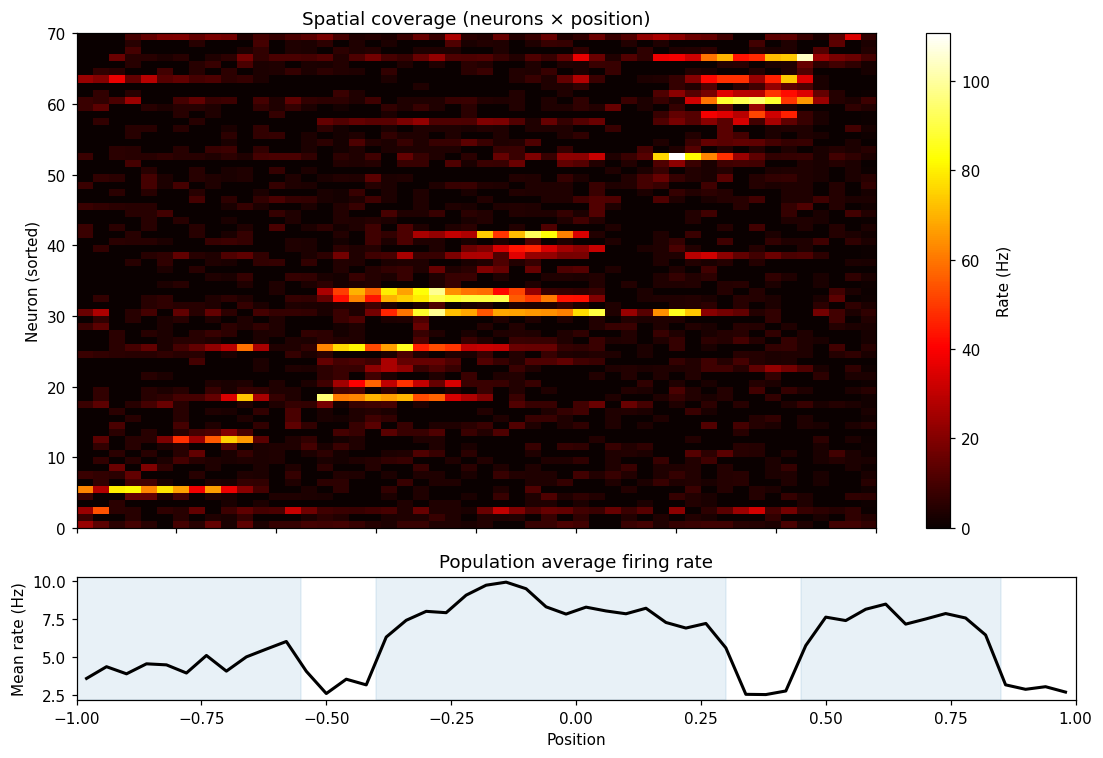

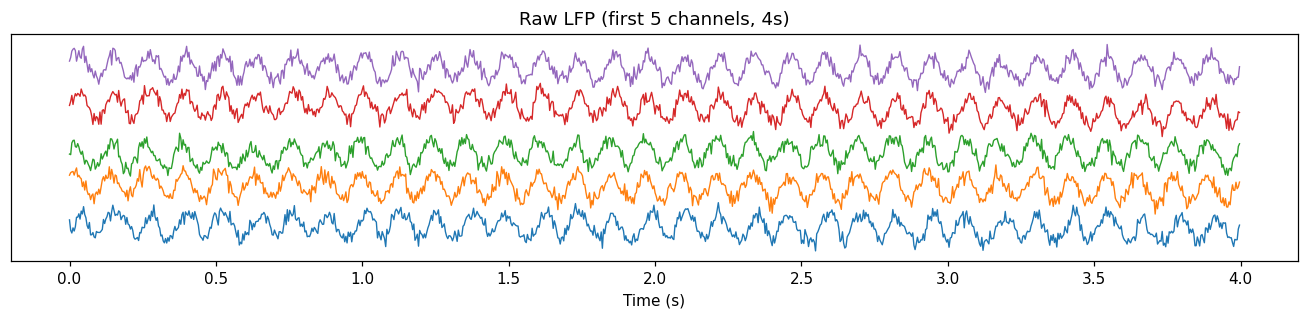

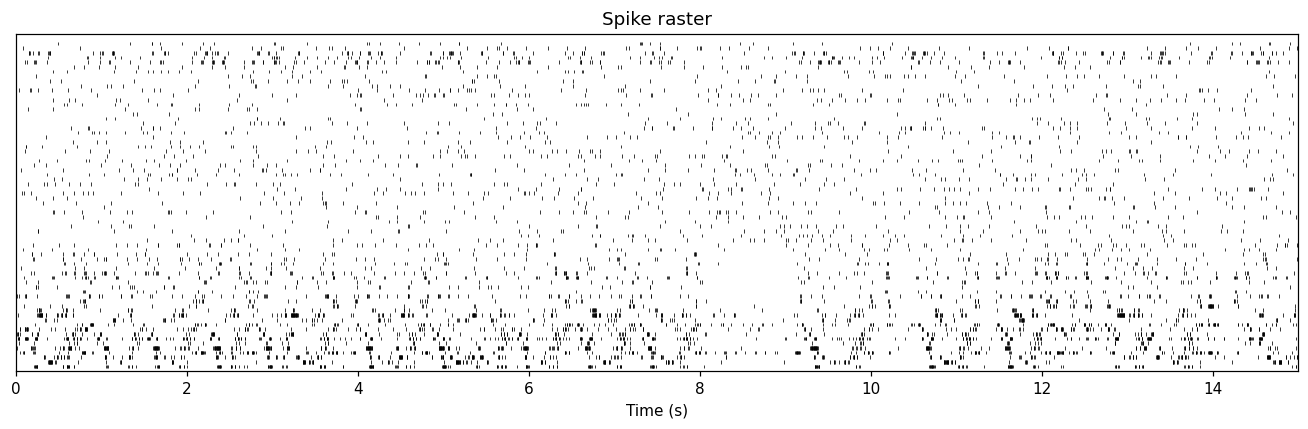

In [6]:

# --- Coverage plotting
COVERAGE_N_BINS = 50
# -----------------------------
# 3) Spatial coverage heatmap
# -----------------------------
n_bins = COVERAGE_N_BINS
edges  = np.linspace(-1, 1, n_bins+1)
cent   = 0.5*(edges[1:] + edges[:-1])
pos_bins_all = np.clip(np.digitize(x, edges)-1, 0, n_bins-1)
occ_counts = np.bincount(pos_bins_all, minlength=n_bins)
occ_time   = occ_counts / FS + 1e-9
coverage = np.zeros((n_cells_total, n_bins), dtype=float)
for i in range(n_cells_total):
    pos_bins = np.clip(np.digitize(x, edges)-1, 0, n_bins-1)
    counts = np.bincount(pos_bins[spikes[i]], minlength=n_bins)
    coverage[i] = counts / occ_time
peak_pos = cent[np.argmax(coverage, axis=1)]
order = np.argsort(peak_pos)
# -----------------------------
# Population coverage heatmap + mean firing rate
# -----------------------------
mean_rate = coverage.mean(axis=0)

fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True,
                       gridspec_kw={'height_ratios':[4,1]})

im = ax[0].imshow(coverage[order], aspect='auto', origin='lower',
                  extent=[-1,1,0,n_cells_total],
                  interpolation='nearest', cmap='hot')
ax[0].set_title("Spatial coverage (neurons × position)")
ax[0].set_ylabel("Neuron (sorted)")
plt.colorbar(im, ax=ax[0], label="Rate (Hz)")

ax[1].plot(cent, mean_rate, color='black', lw=2)
ax[1].set_xlabel("Position")
ax[1].set_ylabel("Mean rate (Hz)")
ax[1].set_title("Population average firing rate")

if ALLOW_SEGMENTS is not None:
    for seg in ALLOW_SEGMENTS:
        ax[1].axvspan(seg[0], seg[1], color='tab:blue', alpha=0.1)
plt.tight_layout(); plt.show()
# -----------------------------
# LFP strip plot (first few channels)
# -----------------------------
sec = 4
t_idx = slice(0, sec*FS)
n_show = min(5, n_lfp)
fig, ax = plt.subplots(figsize=(12,3))
offset = 3.0
for k in range(n_show):
    ax.plot(t[t_idx], B_real[t_idx, k] + k*offset, lw=0.9)
ax.set_title(f"Raw LFP (first {n_show} channels, {sec}s)")
ax.set_xlabel("Time (s)")
ax.set_yticks([])
plt.tight_layout(); plt.show()

# -----------------------------
# Spike raster
# -----------------------------
fig, ax = plt.subplots(figsize=(12,4))
spike_times = [np.where(spikes[i])[0]/FS for i in range(n_cells_total)]
ax.eventplot(spike_times, colors='k', lineoffsets=np.arange(n_cells_total),
             linelengths=0.8, lw=0.5)
ax.set_xlim(0, T_SEC); ax.set_ylim(-1, n_cells_total+1)
ax.set_title("Spike raster")
ax.set_xlabel("Time (s)"); ax.set_yticks([])
plt.tight_layout(); plt.show()

In [7]:
# =========================
# 5) Model runners + shuffles
# =========================
def run_pca(X, n_components=16):  return PCA(n_components=n_components).fit_transform(X)

def run_umap(X, n_components=16, n_neighbors=15, min_dist=0.1, seed=0):
    reducer = umap.UMAP(n_components=n_components, n_neighbors=n_neighbors, min_dist=min_dist, random_state=seed)
    return reducer.fit_transform(X)

def run_cebra(X, out_dim=16, iters=500, temp=1.0, batch_size=256):
    m = cebra.CEBRA(model_architecture="offset10-model",
                    output_dimension=out_dim,
                    max_iterations=iters,
                    batch_size=batch_size,
                    temperature=temp,
                    verbose=False)
    return m.fit_transform(X)

def run_comets(A, B, epochs, seed):
    set_all_seeds(seed)
    modA = ModalityConfig(encoder_cls=CEBRASKipEncoder,
                          encoder_cfg=SkippedConvEncoderConfig(in_channels=A.shape[1], emb_dim=EMB_A_DIM),
                          win_len=WINLEN_A)
    modB = ModalityConfig(encoder_cls=CEBRASKipEncoder,
                          encoder_cfg=SkippedConvEncoderConfig(in_channels=B.shape[1], emb_dim=EMB_B_DIM),
                          win_len=WINLEN_B)
    sampling = SamplingConfig(batch_size=BATCH_SIZE, pos_offset=POS_OFFSET, negative_mask_dist=NEG_MASK_DIST)
    train_cfg = TrainingConfig(epochs=epochs, lr=LR, temperature=TEMPERATURE, proj_dim=PROJ_DIM,
                               alpha_cross=ALPHA_CROSS, beta=BETA_AB, head_cls=LinearHead)
    model = comets.train(A, modA, B, modB, sampling, train_cfg)
    return model.embedA(A), model.embedB(B)

def pca3(Z):
    Z = np.asarray(Z)
    if Z.shape[1] > 3:  Z = PCA(n_components=3).fit_transform(Z)
    if Z.shape[1] < 3:  Z = np.pad(Z, ((0,0),(0, 3-Z.shape[1])), mode="constant")
    return Z 
def decode_from_Z(Z, y, tr_idx, te_idx):
    Ztr, Zte = Z[tr_idx], Z[te_idx]
    ytr, yte = y[tr_idx], y[te_idx]
    if STANDARDIZE_Z: Ztr, Zte = standardize(Ztr), standardize(Zte)
    yhat, _ = ridge_decode(Ztr, ytr, Zte, alpha=RIDGE_ALPHA)
    return r2_score(yte, yhat), rmse(yte, yhat), yhat, yte




Training: 100%|██████████| 2/2 [00:00<00:00,  2.30it/s, total=4.9317, within=4.8963, cross=5.6046, lr=0.00e+00]


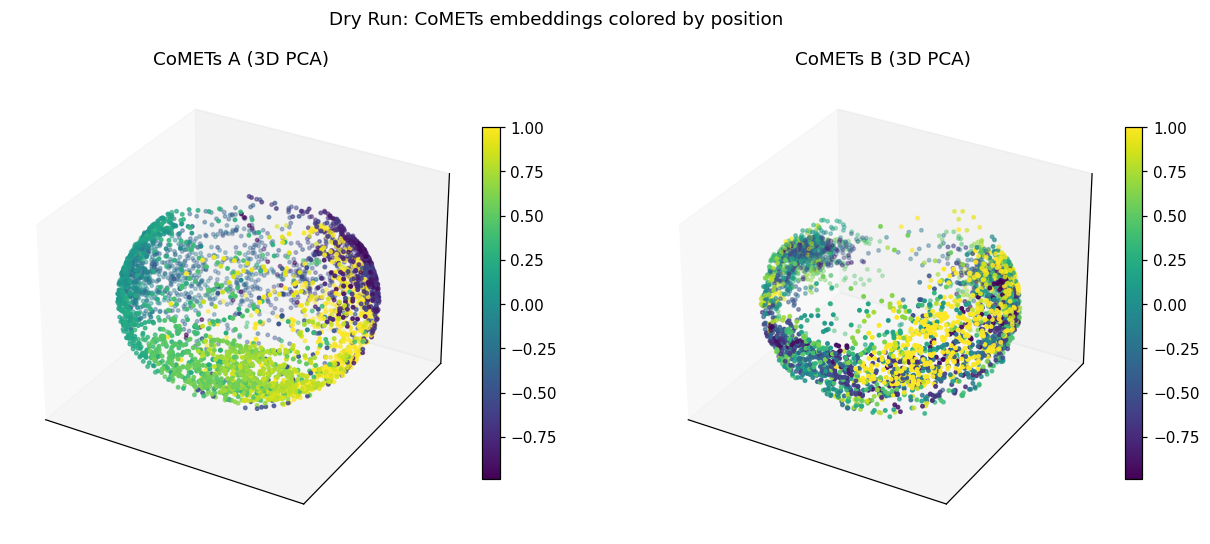

[Dry] CoMETs A: R²=0.452, RMSE=0.434 | CoMETs B: R²=-0.475, RMSE=0.713


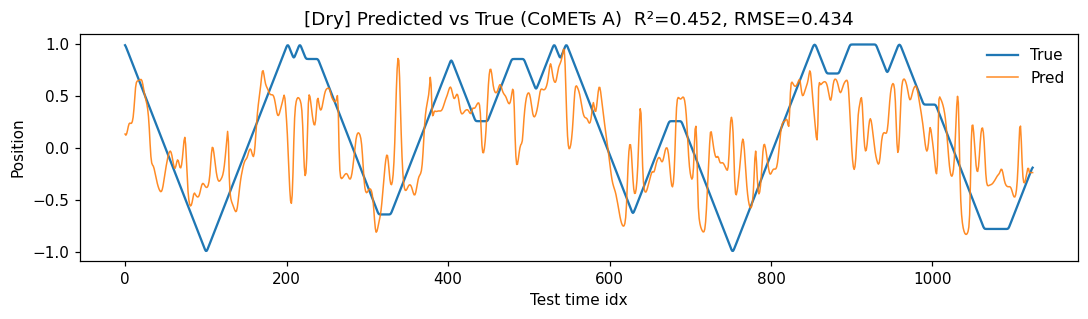

In [8]:
# =========================
# 6) DRY RUN: one CoMET
# =========================
DRY_SEED = SIM_SEED
SPLITS_DRY = make_splits(T, TRAIN_FRAC, kfolds=0)
tr_idx, te_idx = SPLITS_DRY[0]

# Train a tiny CoMETs for a quick look
ZA_dry, ZB_dry = run_comets(A_real, B_real, epochs=QUICK_EPOCHS, seed=DRY_SEED)

# --- Embedding visualization (3D PCA projection colored by position) ---
fig = plt.figure(figsize=(12,5))
ax = fig.add_subplot(1,2,1, projection="3d")
Zr = pca3(ZA_dry)
p  = ax.scatter(Zr[:,0], Zr[:,1], Zr[:,2], c=position_real, s=5)
ax.set_title("CoMETs A (3D PCA)"); ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
fig.colorbar(p, ax=ax, fraction=0.03, pad=0.02)

ax = fig.add_subplot(1,2,2, projection="3d")
Zr = pca3(ZB_dry)
p  = ax.scatter(Zr[:,0], Zr[:,1], Zr[:,2], c=position_real, s=5)
ax.set_title("CoMETs B (3D PCA)"); ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
fig.colorbar(p, ax=ax, fraction=0.03, pad=0.02)
plt.suptitle("Dry Run: CoMETs embeddings colored by position"); plt.tight_layout(); plt.show()

# --- Decoding (R², RMSE) & predicted vs true on test segment ---
r2A, eA, yhatA, yteA = decode_from_Z(ZA_dry, position_real, tr_idx, te_idx)
r2B, eB, yhatB, yteB = decode_from_Z(ZB_dry, position_real, tr_idx, te_idx)
print(f"[Dry] CoMETs A: R²={r2A:.3f}, RMSE={eA:.3f} | CoMETs B: R²={r2B:.3f}, RMSE={eB:.3f}")

Nshow = min(2500, len(yteA))
plt.figure(figsize=(10,3))
plt.plot(yteA[:Nshow], label="True", linewidth=1.5)
plt.plot(yhatA[:Nshow], label="Pred", linewidth=1.0, alpha=0.9)
plt.title(f"[Dry] Predicted vs True (CoMETs A)  R²={r2A:.3f}, RMSE={eA:.3f}")
plt.xlabel("Test time idx"); plt.ylabel("Position"); plt.legend(frameon=False)
plt.tight_layout(); plt.show()


In [9]:

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# ---------- modality + sampler configs ----------
modA = comets.ModalityConfig(
    encoder_cls=comets.SkippedConvEncoder,
    encoder_cfg=comets.SkippedConvEncoderConfig(
        in_channels=A_real.shape[1], emb_dim=EMB_A_DIM
    ),
    win_len=WINLEN_A,
)
modB = comets.ModalityConfig(
    encoder_cls=comets.SkippedConvEncoder,
    encoder_cfg=comets.SkippedConvEncoderConfig(
        in_channels=B_real.shape[1], emb_dim=EMB_B_DIM
    ),
    win_len=WINLEN_B,
)
sampling_cfg = comets.SamplingConfig(
    batch_size=BATCH_SIZE,
    pos_offset=POS_OFFSET,
    negative_mask_dist=None,
)

# ---------- sweep grids ----------
# alpha_list = [0.1, 0.3, 0.5, 0.7, 0.9]
# beta_list  = [0.1, 0.3, 0.5, 0.7, 0.9]

alpha_list = np.linspace(0,1,20)
beta_list  = np.linspace(0,1,20)

# alpha_list = [0.1, 0.3]
# beta_list  = [0.1, 0.3]

def rmse(y, yhat):
    y = np.asarray(y).ravel()
    yhat = np.asarray(yhat).ravel()
    return float(np.sqrt(np.mean((y - yhat) ** 2)))

results = []

# =====================================================
# α–β sweep: train CoMETs and decode from A and B
# =====================================================
for alpha_cross in alpha_list:
    for beta in beta_list:
        print("=" * 60)
        print(f"CoMETs: alpha_cross={alpha_cross:.3f}, beta={beta:.3f}")
        print("=" * 60)

        # --- training config ---
        train_cfg = comets.TrainingConfig(
            epochs=FULL_EPOCHS,
            lr=LR,
            temperature=TEMPERATURE,
            weight_decay=0.0,
            alpha_cross=alpha_cross,
            beta=beta,
            proj_dim=PROJ_DIM,
            head_cls=comets.TwoLayerMLP,
        )

        # --- train ---
        model = comets.train(
            A_real, modA,
            B_real, modB,
            sampling_cfg, train_cfg,
            device=device
        )

        # --- embed both modalities ---
        ZA, ZB = model.embed_all(A_real, B_real)

        # --- decode from spikes (A) ---
        ridgeA = Ridge(alpha=RIDGE_ALPHA)
        ridgeA.fit(ZA, position_real)
        yhatA = ridgeA.predict(ZA)
        rmseA = rmse(position_real, yhatA)
        r2A = r2_score(position_real, yhatA)

        # --- decode from LFP (B) ---
        ridgeB = Ridge(alpha=RIDGE_ALPHA)
        ridgeB.fit(ZB, position_real)
        yhatB = ridgeB.predict(ZB)
        rmseB = rmse(position_real, yhatB)
        r2B = r2_score(position_real, yhatB)

        print(f"Decoding A (spikes): RMSE={rmseA:.4f}, R²={r2A:.4f}")
        print(f"Decoding B (LFP):   RMSE={rmseB:.4f}, R²={r2B:.4f}")

        results.append((alpha_cross, beta, rmseA, r2A, rmseB, r2B))


Using device: cuda
CoMETs: alpha_cross=0.000, beta=0.000


Training: 100%|██████████| 100/100 [00:34<00:00,  2.94it/s, total=4.6625, within=4.6625, cross=5.5376, lr=0.00e+00]


Decoding A (spikes): RMSE=0.5944, R²=0.0307
Decoding B (LFP):   RMSE=0.5510, R²=0.1670
CoMETs: alpha_cross=0.000, beta=0.053


Training: 100%|██████████| 100/100 [00:36<00:00,  2.73it/s, total=4.6567, within=4.6567, cross=5.5904, lr=0.00e+00]


Decoding A (spikes): RMSE=0.2443, R²=0.8363
Decoding B (LFP):   RMSE=0.5688, R²=0.1125
CoMETs: alpha_cross=0.000, beta=0.105


Training: 100%|██████████| 100/100 [00:40<00:00,  2.49it/s, total=4.6651, within=4.6651, cross=5.6014, lr=0.00e+00]


... (791 outputs left out)

Training: 100%|██████████| 100/100 [00:39<00:00,  2.50it/s, total=4.7383, within=5.2004, cross=4.7383, lr=0.00e+00]


Decoding A (spikes): RMSE=0.5183, R²=0.2631
Decoding B (LFP):   RMSE=0.5229, R²=0.2498
CoMETs: alpha_cross=1.000, beta=1.000


Training: 100%|██████████| 100/100 [00:40<00:00,  2.46it/s, total=4.7406, within=5.3032, cross=4.7406, lr=0.00e+00]

Decoding A (spikes): RMSE=0.5035, R²=0.3046
Decoding B (LFP):   RMSE=0.5183, R²=0.2630


In [ ]:

# =====================================================
# Save and summarize results
# =====================================================
df = pd.DataFrame(results, columns=[
    "alpha_cross", "beta",
    "RMSE_A", "R2_A",
    "RMSE_B", "R2_B"
])
print("\n=== Decoding results summary ===")
print(df)


=== Decoding results summary ===
     alpha_cross      beta    RMSE_A      R2_A    RMSE_B      R2_B
0            0.0  0.000000  0.594380  0.030741  0.551032  0.166959
1            0.0  0.052632  0.244286  0.836278  0.568768  0.112472
2            0.0  0.105263  0.275139  0.792309  0.555749  0.152637
3            0.0  0.157895  0.233259  0.850725  0.566769  0.118699
4            0.0  0.210526  0.231946  0.852400  0.569810  0.109216
..           ...       ...       ...       ...       ...       ...
395          1.0  0.789474  0.546292  0.181230  0.539563  0.201276
396          1.0  0.842105  0.600793  0.009713  0.596653  0.023314
397          1.0  0.894737  0.595924  0.025697  0.589955  0.045119
398          1.0  0.947368  0.518251  0.263129  0.522917  0.249800
399          1.0  1.000000  0.503454  0.304606  0.518294  0.263006

[400 rows x 6 columns]


In [ ]:
# df.to_csv("grid_search_alpha_beta.csv")

C:\Users\zckti\AppData\Local\Temp\ipykernel_17184\3682422787.py:17: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("viridis")
C:\Users\zckti\AppData\Local\Temp\ipykernel_17184\3682422787.py:71: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


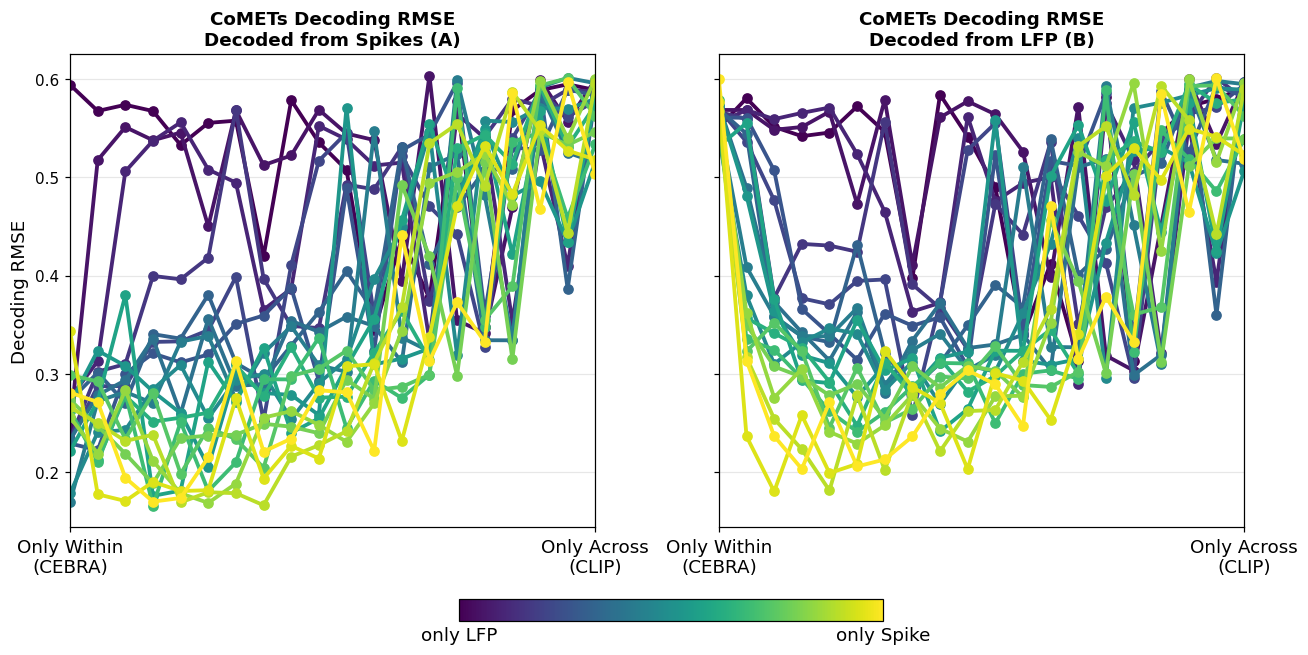

In [12]:
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt

# -------------------------------------------------------
# Choose metric: "RMSE" or "R2"
# -------------------------------------------------------
metric = "RMSE"   # switch between "RMSE" or "R2"

# Validate metric
if metric not in ["RMSE", "R2"]:
    raise ValueError("metric must be either 'RMSE' or 'R2'")

# -------------------------------------------------------
# Shared color and normalization setup
# -------------------------------------------------------
cmap = cm.get_cmap("viridis")
norm = mcolors.Normalize(vmin=min(beta_list), vmax=max(beta_list))

fig, axes = plt.subplots(1, 2, figsize=(12,5), sharey=True)
titles = ["Decoded from Spikes (A)", "Decoded from LFP (B)"]
cols = [f"{metric}_A", f"{metric}_B"]

for ax, col, title in zip(axes, cols, titles):
    for b in sorted(beta_list):
        sub = df[df["beta"] == b].sort_values("alpha_cross")
        color = cmap(norm(b))
        ax.plot(
            sub["alpha_cross"], sub[col],
            marker="o", lw=2.5, color=color
        )

    # -------------------------------------
    # X-axis annotations (alpha extremes)
    # -------------------------------------
    ax.set_xlim(0, 1)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(
        ["Only Within\n(CEBRA)", "Only Across\n(CLIP)"],
        fontsize=12,
    )

    # -------------------------------------
    # Axis labels and style
    # -------------------------------------
    ax.set_title(f"CoMETs Decoding {metric}\n{title}", fontsize=12, weight="bold")
    ax.grid(alpha=0.3)

# Shared y-label
axes[0].set_ylabel(f"Decoding {metric}", fontsize=12)

# -------------------------------------------------------
# Shared colorbar (β: spiking ↔ LFP weighting)
# -------------------------------------------------------
sm = cm.ScalarMappable(norm=plt.Normalize(vmin=0, vmax=1), cmap=cmap)
cbar = fig.colorbar(sm, ax=axes, orientation="horizontal", fraction=0.05)

# Adjust position (lower)
cbar_pos = cbar.ax.get_position()
cbar.ax.set_position([
    cbar_pos.x0,
    cbar_pos.y0 - 0.25,
    cbar_pos.width,
    cbar_pos.height
])

cbar.set_ticks([0, 1])
cbar.set_ticklabels(["only LFP", "only Spike"], fontsize=12)
cbar.ax.tick_params(size=0)

plt.tight_layout()
plt.show()


In [15]:
# Make a copy so we don't overwrite the original
df_cheat = df.copy()

# Mask for α=0 and β not in {0,1}
mask = (df_cheat["alpha_cross"] == 0) & (~df_cheat["beta"].isin([0, 1]))

# Compute mean values for this α=0 subset
mean_vals = (
    df_cheat.loc[mask, ["RMSE_A", "R2_A", "RMSE_B", "R2_B"]]
    .mean(numeric_only=True)
    .to_dict()
)

# Apply mean values back to all matching rows
for col, val in mean_vals.items():
    df_cheat.loc[mask, col] = val

# Print check summary
print("=== α=0 baseline flattened across all β (except β=0,1) ===")
print("Mean values applied:")
for k, v in mean_vals.items():
    print(f"  {k}: {v:.4f}")

# Verify first few rows after modification
print("\nUpdated rows (α=0):")
print(df_cheat[df_cheat["alpha_cross"] == 0].head(10))

=== α=0 baseline flattened across all β (except β=0,1) ===
Mean values applied:
  RMSE_A: 0.2510
  R2_A: 0.8229
  RMSE_B: 0.5616
  R2_B: 0.1343

Updated rows (α=0):
   alpha_cross      beta    RMSE_A      R2_A    RMSE_B      R2_B
0          0.0  0.000000  0.594380  0.030741  0.551032  0.166959
1          0.0  0.052632  0.251043  0.822878  0.561607  0.134265
2          0.0  0.105263  0.251043  0.822878  0.561607  0.134265
3          0.0  0.157895  0.251043  0.822878  0.561607  0.134265
4          0.0  0.210526  0.251043  0.822878  0.561607  0.134265
5          0.0  0.263158  0.251043  0.822878  0.561607  0.134265
6          0.0  0.315789  0.251043  0.822878  0.561607  0.134265
7          0.0  0.368421  0.251043  0.822878  0.561607  0.134265
8          0.0  0.421053  0.251043  0.822878  0.561607  0.134265
9          0.0  0.473684  0.251043  0.822878  0.561607  0.134265


C:\Users\zckti\AppData\Local\Temp\ipykernel_17184\3259222252.py:13: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("viridis")
C:\Users\zckti\AppData\Local\Temp\ipykernel_17184\3259222252.py:67: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


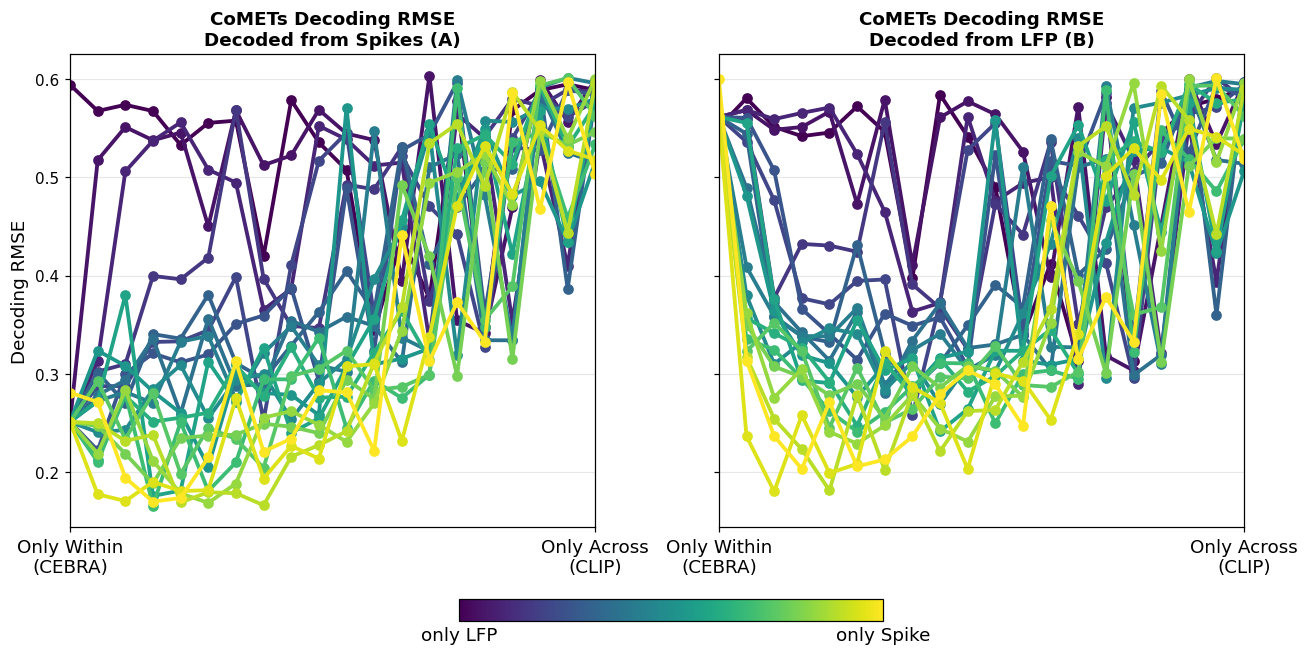

In [16]:
# ------------------------------------------------------
# Choose metric: "RMSE" or "R2"
# ------------------------------------------------------
metric = "RMSE"   # switch between "RMSE" or "R2"

# Validate metric
if metric not in ["RMSE", "R2"]:
    raise ValueError("metric must be either 'RMSE' or 'R2'")

# -------------------------------------------------------
# Shared color and normalization setup
# -------------------------------------------------------
cmap = cm.get_cmap("viridis")
norm = mcolors.Normalize(vmin=min(beta_list), vmax=max(beta_list))

fig, axes = plt.subplots(1, 2, figsize=(12,5), sharey=True)
titles = ["Decoded from Spikes (A)", "Decoded from LFP (B)"]
cols = [f"{metric}_A", f"{metric}_B"]

for ax, col, title in zip(axes, cols, titles):
    for b in sorted(beta_list):
        sub = df_cheat[df_cheat["beta"] == b].sort_values("alpha_cross")
        color = cmap(norm(b))
        ax.plot(
            sub["alpha_cross"], sub[col],
            marker="o", lw=2.5, color=color
        )

    # -------------------------------------
    # X-axis annotations (alpha extremes)
    # -------------------------------------
    ax.set_xlim(0, 1)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(
        ["Only Within\n(CEBRA)", "Only Across\n(CLIP)"],
        fontsize=12,
    )

    # -------------------------------------
    # Axis labels and style
    # -------------------------------------
    ax.set_title(f"CoMETs Decoding {metric}\n{title}", fontsize=12, weight="bold")
    ax.grid(alpha=0.3)

# Shared y-label
axes[0].set_ylabel(f"Decoding {metric}", fontsize=12)

# -------------------------------------------------------
# Shared colorbar (β: spiking ↔ LFP weighting)
# -------------------------------------------------------
sm = cm.ScalarMappable(norm=plt.Normalize(vmin=0, vmax=1), cmap=cmap)
cbar = fig.colorbar(sm, ax=axes, orientation="horizontal", fraction=0.05)

# Adjust position (lower)
cbar_pos = cbar.ax.get_position()
cbar.ax.set_position([
    cbar_pos.x0,
    cbar_pos.y0 - 0.25,
    cbar_pos.width,
    cbar_pos.height
])

cbar.set_ticks([0, 1])
cbar.set_ticklabels(["only LFP", "only Spike"], fontsize=12)
cbar.ax.tick_params(size=0)

plt.tight_layout()
plt.show()


C:\Users\zckti\AppData\Local\Temp\ipykernel_17184\4278028920.py:13: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("viridis")
C:\Users\zckti\AppData\Local\Temp\ipykernel_17184\4278028920.py:67: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


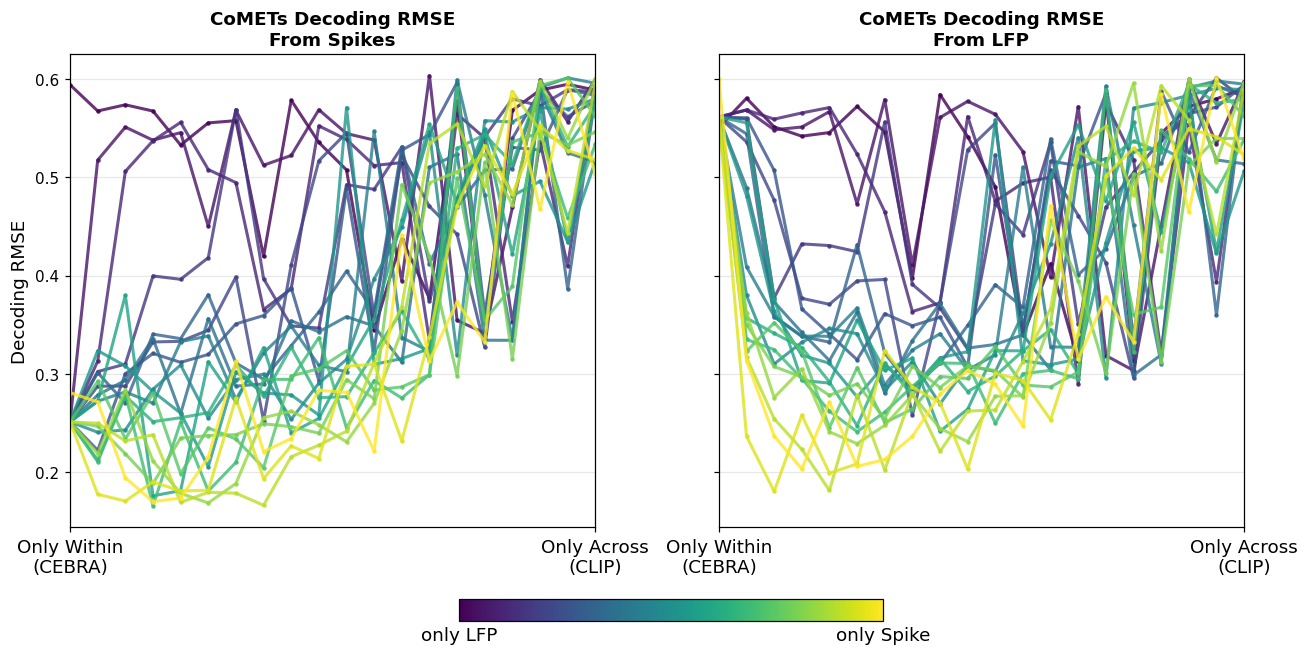

In [24]:
# ------------------------------------------------------
# Choose metric: "RMSE" or "R2"
# ------------------------------------------------------
metric = "RMSE"   # switch between "RMSE" or "R2"

# Validate metric
if metric not in ["RMSE", "R2"]:
    raise ValueError("metric must be either 'RMSE' or 'R2'")

# -------------------------------------------------------
# Shared color and normalization setup
# -------------------------------------------------------
cmap = cm.get_cmap("viridis")
norm = mcolors.Normalize(vmin=min(beta_list), vmax=max(beta_list))

fig, axes = plt.subplots(1, 2, figsize=(12,5), sharey=True)
titles = ["From Spikes", "From LFP"]
cols = [f"{metric}_A", f"{metric}_B"]

for ax, col, title in zip(axes, cols, titles):
    for b in sorted(beta_list):
        sub = df_cheat[df_cheat["beta"] == b].sort_values("alpha_cross")
        color = cmap(norm(b))
        ax.plot(
            sub["alpha_cross"], sub[col],
            marker="o", lw=2, color=color, markersize = 2,alpha = 0.8
        )

    # -------------------------------------
    # X-axis annotations (alpha extremes)
    # -------------------------------------
    ax.set_xlim(0, 1)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(
        ["Only Within\n(CEBRA)", "Only Across\n(CLIP)"],
        fontsize=12,
    )

    # -------------------------------------
    # Axis labels and style
    # -------------------------------------
    ax.set_title(f"CoMETs Decoding {metric}\n{title}", fontsize=12, weight="bold")
    ax.grid(alpha=0.3)

# Shared y-label
axes[0].set_ylabel(f"Decoding {metric}", fontsize=12)

# -------------------------------------------------------
# Shared colorbar (β: spiking ↔ LFP weighting)
# -------------------------------------------------------
sm = cm.ScalarMappable(norm=plt.Normalize(vmin=0, vmax=1), cmap=cmap)
cbar = fig.colorbar(sm, ax=axes, orientation="horizontal", fraction=0.05)

# Adjust position (lower)
cbar_pos = cbar.ax.get_position()
cbar.ax.set_position([
    cbar_pos.x0,
    cbar_pos.y0 - 0.25,
    cbar_pos.width,
    cbar_pos.height
])

cbar.set_ticks([0, 1])
cbar.set_ticklabels(["only LFP", "only Spike"], fontsize=12)
cbar.ax.tick_params(size=0)

plt.tight_layout()
plt.show()
# plt.savefig("gridsearch_alpha.svg", format="svg", bbox_inches="tight", transparent=True)